Our goal is to build a classifier that distinguishes vowels using the formant frequency measurements contained in the 1995 Hillenbrand vowel data set.

In this notebook, we'll use `sklearn`'s [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) model to review the classical workflow.

## Logistic Regression

### Minimal Implementation

First, we split our data into train/test sets by speaker, so that no speaker appears in both, stratifying by speaker category. Every speaker recorded all 12 vowels, so both sets are exactly class-balanced.

In [222]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, f1_score
from sklearn.pipeline import Pipeline 

In [223]:
# generated (Claude): hold out ~20% of speakers, stratified by category.
# Split on speakers, not rows, so no speaker appears in both sets. Every model uses this split.
speakers = data[['speaker_id', 'category']].drop_duplicates()
train_spk, test_spk = train_test_split(
    speakers['speaker_id'], test_size=0.2, stratify=speakers['category'], random_state=42
)
train = data[data['speaker_id'].isin(train_spk)]
test = data[data['speaker_id'].isin(test_spk)]
assert not set(train['speaker_id']) & set(test['speaker_id'])

X_train, y_train = train[feature_cols].to_numpy(), train['label'].to_numpy()
X_test, y_test = test[feature_cols].to_numpy(), test['label'].to_numpy()
print(f'train: {len(train_spk)} speakers, {len(train)} rows | test: {len(test_spk)} speakers, {len(test)} rows')
test.groupby('category')['speaker_id'].nunique()

train: 111 speakers, 1332 rows | test: 28 speakers, 336 rows


category
b     5
g     4
m     9
w    10
Name: speaker_id, dtype: int64

Ordinarily, we'd next scale our data. We've already performed Lobanov normalization, so our data already has zero mean and unit variance. Otherwise, we'd use the [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) before proceeding.

Next, we configure our `LogisticRegression` model with L2 regularization.

In [224]:
logreg1 = LogisticRegression(
    C=1.0,
    solver='lbfgs',
)

We can now fit our training data, and evaluate accuracy.

In [225]:
logreg1.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [226]:
predictions = logreg1.predict(X_test)
probabilities = logreg1.predict_proba(X_test)

In [227]:
print(accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

0.9672619047619048
              precision    recall  f1-score   support

           0       0.93      0.96      0.95        28
           1       0.96      0.96      0.96        28
           2       0.93      0.96      0.95        28
           3       0.96      0.89      0.93        28
           4       0.96      0.96      0.96        28
           5       1.00      1.00      1.00        28
           6       0.97      1.00      0.98        28
           7       0.96      0.96      0.96        28
           8       0.96      0.96      0.96        28
           9       1.00      1.00      1.00        28
          10       1.00      0.96      0.98        28
          11       0.96      0.96      0.96        28

    accuracy                           0.97       336
   macro avg       0.97      0.97      0.97       336
weighted avg       0.97      0.97      0.97       336



The confusion matrix below shows per-class performance.

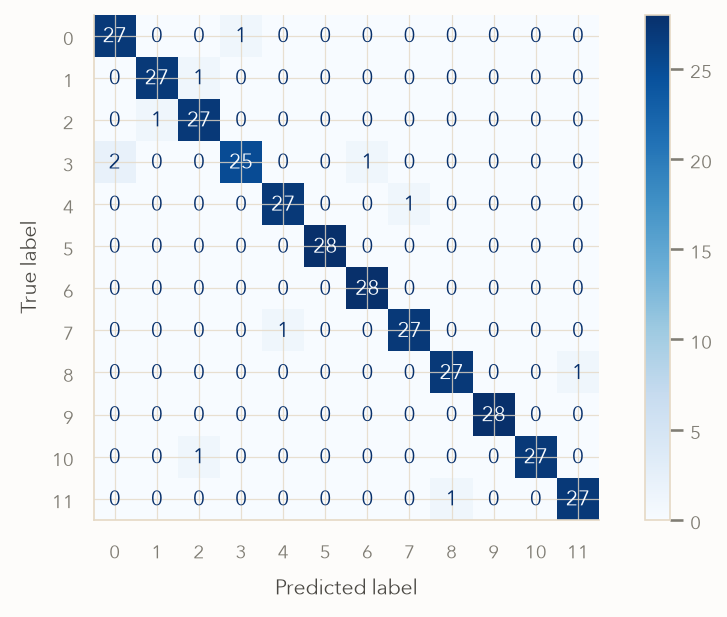

In [228]:
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)

Accuracy at 97% looks good, but all this tells us is that our data is ready for modeling—not that the model is truly performant.

There are major issues with the approach we took above:

- `train_test_split` generates _one_ split, on which the output depends completely. Without additional data, we can't judge confidence in our evaluations of the model.
- We haven't varied hyperparameters like regularization strength, so we don't know if `C = 1.0` is optimal.

We can fix this by using **stratified group k-fold cross validation** and grid search.

### Stratified Group K-Fold Cross Validation

Instead of generating a single train/test split, we can split the training data into `k` equal parts, called **folds**; train the model on `k-1` folds; evaluate it on the holdout; and repeat `k` times. This procedure is called **k-fold cross validation**. Telling `sklearn` to `stratify` the folds guarantees that each one contains the same proportion of class labels as the original data set. Stratification is particularly important on imbalanced datasets, and is generally good practice for classification tasks.

In our case, there's an additional constraint. Simple `StratifiedKFold` preserves class proportions, but assumes each row of our data is independent of every other. In fact, every row of our data contains groups of vowels corresponding to specific _speakers_. If some of a speaker's utterances were used in the training set, and some in the test set, the model would likely achieve artificially high performance on the latter due to correlation between the training and test data. This is a form of leakage that occurs when your data contains multiple observations for a given entity; _all_ of the samples associated with a given entity _must_ appear in either the training _or_ holdout folds, but never in both.

In addition, we'll use [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) to automatically optimize hyperparameters.

First, we define the grid of hyperparameters to test:

- `C`: Inverse regularization strength. Lower values mean stronger regularization.
- `solver`: Which optimization algorithm to use. Both minimize the same L2-penalized loss, so they should reach the same solution.

In [229]:
max_iter = 2000
class_weight = None
# ideally, you'd generate results over multiple seeds; we'll just do one here
random_state = 42

In [230]:
param_grid = [
    {
        'logistic__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'logistic__solver': ['lbfgs', 'saga']
    },
]

Next, we define a [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) to wrap our training loop. Any preprocessing steps we add to it later (e.g. a scaler) are then fit on the training folds only, so nothing leaks from the validation fold.

In [231]:
pipeline = Pipeline([
    ('logistic', LogisticRegression(max_iter=max_iter, class_weight=class_weight, random_state=random_state)),
])

And finally, the cross validation strategy.

In [232]:
# 5 and 10 are common defaults
n_splits = 5

In [233]:
cv_strategy = StratifiedGroupKFold(n_splits=n_splits)

To train, we configure a `GridSearchCV` instance with everything, and allow it to manage the training process. It will identify the best combination of parameters, and  retrain the final model on the entire training set (all 111 training speakers) on our behalf.

In [234]:
grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    # macro F1; classes are balanced (139 tokens each), so this tracks accuracy closely
    scoring='f1_macro',
    # all cores
    n_jobs=-1,
)

In [235]:
# The 28 test speakers from the split above never enter cross-validation; they're scored once, at the end.
X, y = X_train, y_train
cv_groups = train['speaker_id'].to_numpy()  # one group per speaker

In [236]:
grid_search.fit(X, y, groups=cv_groups)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'logistic__C': [0.001, 0.01, ...], 'logistic__solver': ['lbfgs', 'saga']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro...shuffle=False)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: i

Grid search opts for weaker regularization than we used initially, with `C=10`.

In [237]:
best_params = grid_search.best_params_
best_params

{'logistic__C': 10, 'logistic__solver': 'saga'}

Anyway, we now have a model to evaluate. The workflow is:

- **Verify cross validation stability**: study the variance in performance across folds; low variance indicates a more stable model.
- **Holistic Evaluation**: `classification_report` on the model's predictions over the held-out test set.
- **Odds Ratios**: Inspect the feature vectors to study which features the model considers predictive.

After that, we'll compute bootstrap confidence intervals for the model's coefficients and evaluation metrics.

First, we'll inspect the model's performance on each fold.

In [238]:
cv_results = pd.DataFrame(grid_search.cv_results_)

In [239]:
best_index = grid_search.best_index_
best_row = cv_results.loc[best_index]

In [240]:
fold_scores = [best_row[f'split{i}_test_score'] for i in range(grid_search.n_splits_)]

In [241]:
print(f"Mean CV Score: {best_row['mean_test_score']:.4f}")
print(f"Fold Score Std Dev: {best_row['std_test_score']:.4f}")
print(f"Per-Fold Scores: {[round(s, 4) for s in fold_scores]}")

Mean CV Score: 0.9752
Fold Score Std Dev: 0.0062
Per-Fold Scores: [np.float64(0.9783), np.float64(0.9659), np.float64(0.9811), np.float64(0.9697), np.float64(0.981)]


There's very little variance between folds. If performance tanked occasionally, it might be a sign of overfitting or misconfiguration. There's no signal here, though, so we move on.

Next, we'll print the `classification_report` to see precision; recall; F1; and accuracy.

In [242]:
pred = grid_search.predict(X_test)
proba = grid_search.predict_proba(X_test)  # (n_test, 12): one column per class, each row sums to 1

In [243]:
print(classification_report(y_test, pred, target_names=VOWELS, digits=3))
print('macro one-vs-rest ROC-AUC:', round(roc_auc_score(y_test, proba, multi_class='ovr', average='macro'), 4))

              precision    recall  f1-score   support

          ae      1.000     0.964     0.982        28
          ah      1.000     0.929     0.963        28
          aw      0.933     1.000     0.966        28
          eh      0.964     0.964     0.964        28
          ei      0.964     0.964     0.964        28
          er      1.000     1.000     1.000        28
          ih      0.966     1.000     0.982        28
          iy      0.964     0.964     0.964        28
          oa      0.964     0.964     0.964        28
          oo      1.000     1.000     1.000        28
          uh      1.000     1.000     1.000        28
          uw      0.964     0.964     0.964        28

    accuracy                          0.976       336
   macro avg      0.977     0.976     0.976       336
weighted avg      0.977     0.976     0.976       336

macro one-vs-rest ROC-AUC: 0.9996


In [244]:
# generated (Claude): the same predictions, scored against listeners instead of the intended vowel
pred_vowel = np.array(VOWELS)[pred]
misid_test = test['misid'].to_numpy()
print(f"model vs intended vowel:     {(pred_vowel == test['vowel']).mean():.3f}")
print(f"model vs listener majority:  {(pred_vowel == test['vote']).mean():.3f}")
print(f"listeners vs intended vowel: {(test['vote'] == test['vowel']).mean():.3f}")
print(f"{misid_test.sum()} test tokens misidentified by listeners; on these the model matches "
      f"the intended vowel {(pred_vowel[misid_test] == test['vowel'][misid_test]).sum()} times "
      f"and the listener vote {(pred_vowel[misid_test] == test['vote'][misid_test]).sum()} times")

model vs intended vowel:     0.976
model vs listener majority:  0.949
listeners vs intended vowel: 0.973
9 test tokens misidentified by listeners; on these the model matches the intended vowel 9 times and the listener vote 0 times


These metrics indicate the following:

- **Accuracy**: Percentage of correct predictions across all classes. Computed as the total number of correctly predicted instances, divided by the total size of the dataset. Misleading in the presence of imbalanced data.
- **Precision**: The proportion of times a model is correct when predicting a specific class, on a per-class basis. High precision implies a low false positives amongst predictions for the class. This is important in situations where false positives are deadly, such as forensic DNA matching.
- **Recall**: The proportion of actual instances of a specific class that the model successfully recovered. Computed per class. High recall is desirable when false negatives are undesirable.
- **F1 Score**: The harmonic mean between precision and recall. Can be calculated per class or aggregated across all $N$ classes. Useful for striking a balance in general modeling and evaluating performance on unbalanced data sets.
- **ROC-AUC**: Measures a model's ability to distinguish between all different classes. In a multiclass setting, this is evaluated by comparing each class against all others combined, or comparing each class against every other.

Precision, recall, and F1 score produce unique values for each class in the multiclass setting. They are often collapsed into global scores according to one of the following approaches:

- **Macro Average**: Calculate the metric independently for each class, then take a simple average. Treats all classes equally, which can have deleterious effects on models over unbalanced data.
- **Weighted Average**: Calculate the metric independently for each class, but weight by **support**, i.e., the number of true instances in each class.

We can view the model's specific classification errors with a confusion matrix, and plot them alongside a ROC curve.

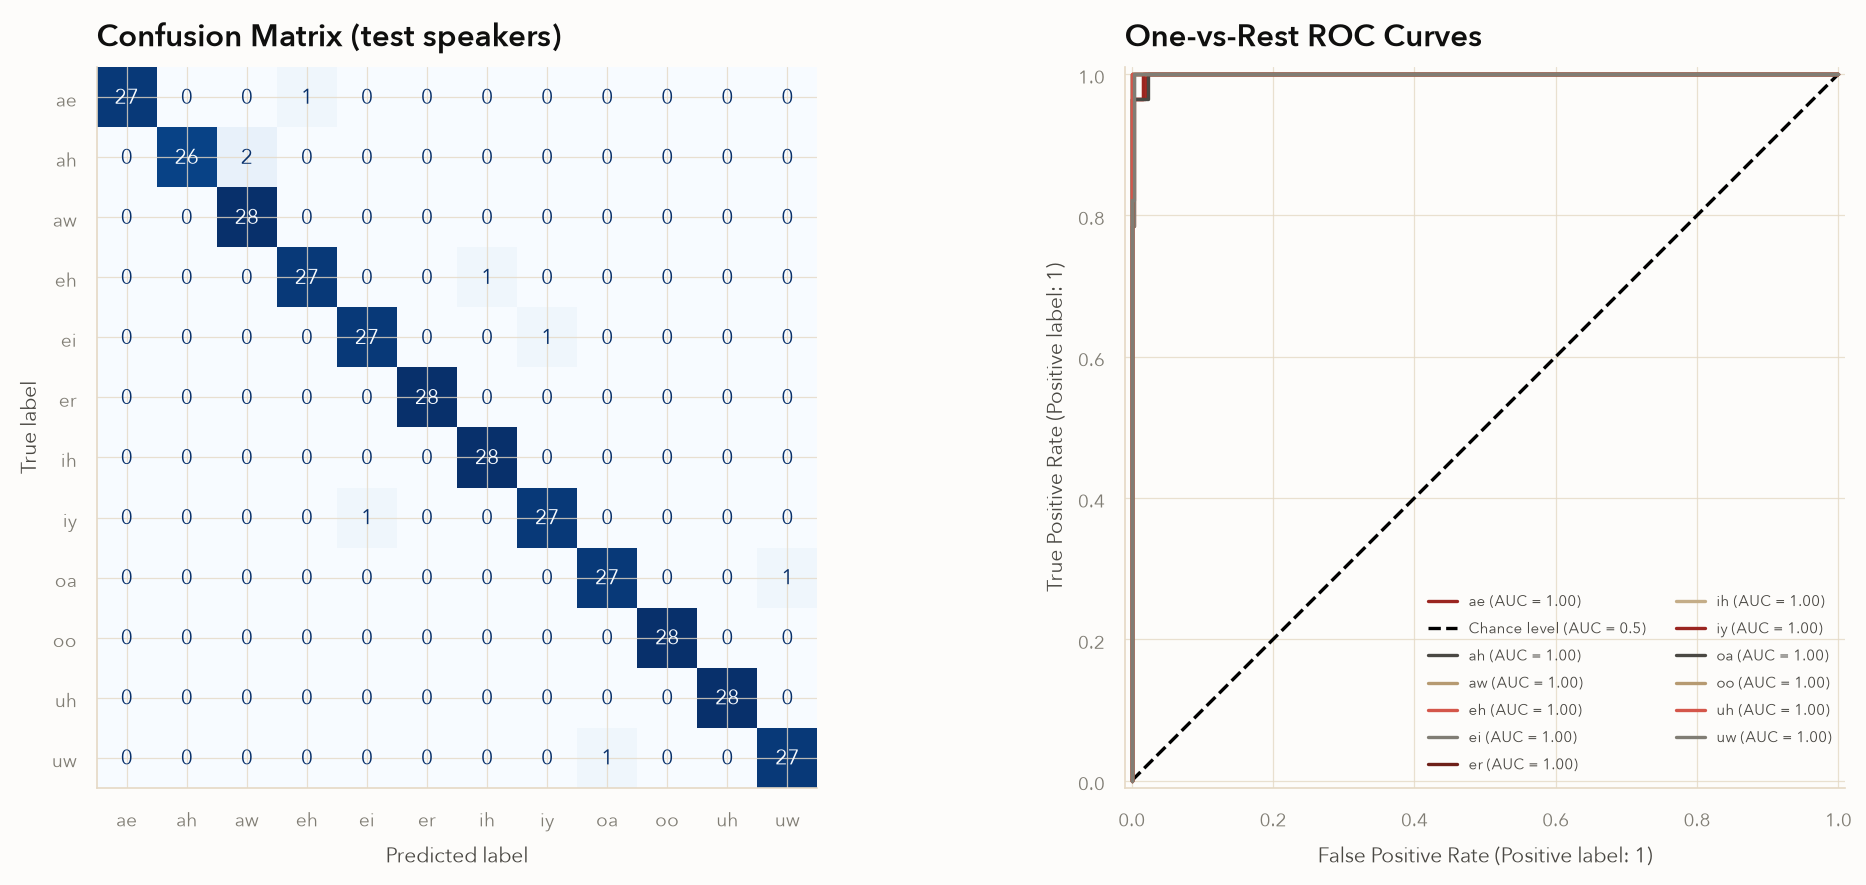

In [245]:
# generated (Claude): ROC is one-vs-rest here: one curve per vowel, that vowel vs. the other 11
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=VOWELS, ax=ax[0], cmap='Blues', colorbar=False,
)
ax[0].set_title('Confusion Matrix (test speakers)')

for k, vowel in enumerate(VOWELS):
    RocCurveDisplay.from_predictions(
        y_test == k, proba[:, k], name=vowel, ax=ax[1], plot_chance_level=(k == 0),
    )
ax[1].set_title('One-vs-Rest ROC Curves')
ax[1].legend(fontsize=7, ncol=2, loc='lower right')

plt.tight_layout()
plt.show()

The confusion matrix indicates strong performance, and the OvR ROC curve indicates correspondingly strong class discrimination.

Finally, we'll extract the log odds from the model and transform them into odds ratios.

In [246]:
best_pipeline = grid_search.best_estimator_
best_model = best_pipeline.named_steps['logistic']
feature_names = feature_cols
best_model.coef_.shape  # (classes, features): one coefficient vector per vowel

(12, 20)

In [247]:
# generated (Claude): rows are vowels, columns are features
coef = pd.DataFrame(best_model.coef_, index=VOWELS, columns=feature_names)
odds_ratios = np.exp(coef)
coef.round(2)

,f1_ss_lbnv,f1_20_lbnv,f1_50_lbnv,f1_80_lbnv,f2_ss_lbnv,f2_20_lbnv,f2_50_lbnv,f2_80_lbnv,f3_ss_lbnv,f3_20_lbnv,f3_50_lbnv,f3_80_lbnv,duration_ms_lbnv,f2_ss_missing,f2_50_missing,f2_80_missing,f3_ss_missing,f3_20_missing,f3_50_missing,f3_80_missing
ae,1.99,0.70,3.96,4.43,4.50,4.43,3.15,0.53,0.75,0.43,-0.20,-1.29,1.77,-0.76,-0.76,-0.30,0.11,0.11,0.03,0.03
ah,3.90,2.99,3.50,4.74,-0.32,0.10,-0.72,-0.28,-0.51,1.33,-0.16,-0.10,0.24,-1.87,-1.95,-0.36,-0.01,-0.01,-0.01,0.26
aw,1.36,1.75,2.05,2.84,-3.67,-3.89,-2.89,-2.43,0.92,-1.61,-0.75,0.41,2.28,2.58,2.88,0.63,0.04,0.04,0.04,-0.04
eh,1.72,2.28,1.65,0.27,1.75,1.74,1.05,0.73,0.11,0.30,0.53,1.16,-1.74,-0.80,-0.80,-0.01,-0.05,-0.05,-0.04,-0.06
ei,0.61,1.62,-2.80,-1.55,-0.69,-1.32,3.45,5.32,0.23,-0.93,0.81,1.07,1.46,-0.52,-0.52,-0.52,-1.05,0.27,-0.24,0.56
er,-0.89,-1.06,-1.48,-1.38,-0.18,-0.22,-0.06,0.34,-1.69,-1.08,-1.38,-2.10,1.09,-0.24,-0.24,-0.24,1.52,1.62,1.62,1.48
ih,-2.68,-3.09,-1.48,0.08,1.36,2.27,0.26,-1.87,1.27,0.92,0.36,0.21,-1.45,-0.49,-0.49,-0.25,-0.34,-0.32,-0.37,-0.29
iy,-2.84,-3.23,-1.57,-2.93,4.32,4.46,1.97,1.92,0.65,1.57,0.58,1.32,0.15,-0.00,-0.00,-0.00,1.41,0.08,0.71,-0.17
oa,-0.05,4.45,-0.96,-3.61,-3.14,-1.72,-2.24,-4.54,-0.49,-1.06,-0.30,0.55,1.48,1.02,2.18,1.07,-0.19,-0.14,-0.28,-0.24
oo,-2.14,-3.96,-1.57,0.74,-2.25,-3.24,-1.03,3.54,-0.67,-0.34,-0.08,-0.08,-2.20,-0.71,-0.74,-0.70,-0.49,-0.57,-0.50,-0.48


**Quick review.** Multinomial logistic regression models the probability of each class $k = 1, 2, \dots, K$ using the softmax function.

As highlighted in [scikit-learn User Guide (§1.1.11.2 "Multinomial Case")**](https://scikit-learn.org/stable/modules/linear_model.html#multinomial-case):

> "We deliberately choose to overparameterize the model using $K$ weight vectors for ease of implementation and to preserve the symmetrical inductive bias regarding ordering of classes… This effect becomes especially important when using regularization."

By assigning a unique coefficient vector and intercept to every single class, the probability $p_k$ is modeled symmetrically as:

$$ p_k = \frac{\exp(\beta_{k,0} + \beta_{k,1} x_1 + \dots + \beta_{k,p} x_p)}{\sum_{j=1}^{K} \exp(\beta_{j,0} + \beta_{j,1} x_1 + \dots + \beta_{j,p} x_p)} $$

This ensures that all classes are penalized equally during regularization.

This specifies the log-odds between any two classes $k$ and $l$ as the difference between their respective coefficient vectors:

$$ \ln\left(\frac{p_k}{p_l}\right) = (\beta_{k,0} - \beta_{l,0}) + (\beta_{k,1} - \beta_{l,1}) x_1 + \dots + (\beta_{k,p} - \beta_{l,p}) x_p $$

In this symmetric formulation, `scikit-learn` fits all $K$ coefficient vectors (e.g., a $12 \times 20$ `coef_` matrix for 12 classes and 20 features).

The traditional baseline-class formulation is mathematically equivalent. It represents the exact same model where one baseline class vector (e.g., $\beta_K$) is fixed entirely at zero.

Recall that **relative odds** are the ratio of a class probability to the baseline class probability:

$$
\textrm{Odds}_{k/N} = \frac{p_k}{p_N}
$$


...So the quantity on the left in the first equation is called **relative log odds**.

This means the coefficient $\beta_{i}$ of a logistic regression model measure the expected change in the _log odds_ of class $k$, relative to the baseline class, under a unit change in $x_{i}$.

Humans don't really think in log odds, though, so they aren't good for intuition.

Instead, we can exponentiate the log odds to recover an **odds ratio** (OR), which measures a given class's odds against the average of the all of them.

$$
\textrm{OR} = e^{\beta_{i}}
$$

The odds ratio measures the multiplicative factor by which the odds of an outcome change under a unit change in $x_{i}$:

- $\textrm{OR} = 1$ indicates that the feature has no effect on the outcome.
- $\textrm{OR} < 1$ indicates that the feature has a negative effect on prediction of the outcome. E.g., OR = 0.8 indicates that a unit increase in $x_{i}$ decreases the odds of the outcome by 20%.
- $\textrm{OR} > 1$ indicates that the feature has a positive effect on prediction of the outcome. E.g., OR = 1.5 indicates that a unit increase in $x_{i}$ increases the odds of the outcome by 50%.

We used cross validation, but still can't quantify how confident we should be that our coefficients are reliable, or simply flukes of the dataset (or training process). We can use a process called **bootstrapping** to compute confidence intervals for the coefficients.

In [248]:
# generated (Claude): speaker-level (cluster) bootstrap. Resample whole speakers, not rows,
# because a speaker's 12 tokens are not independent of one another.
rng = np.random.default_rng(random_state)
train_speakers = np.unique(cv_groups)
rows_by_speaker = {s: np.flatnonzero(cv_groups == s) for s in train_speakers}
n_bootstraps = 500
bootstrapped_coefs = []

In [249]:
for _ in range(n_bootstraps):
    # resample speakers with replacement, then take all of each drawn speaker's rows
    boot_speakers = rng.choice(train_speakers, size=len(train_speakers), replace=True)
    idx = np.concatenate([rows_by_speaker[s] for s in boot_speakers])

    # clone resets the fitted weights but keeps the best hyperparameters
    boot_pipe = clone(best_pipeline).fit(X[idx], y[idx])
    bootstrapped_coefs.append(boot_pipe.named_steps['logistic'].coef_)  # (12, 20)

bootstrapped_coefs = np.stack(bootstrapped_coefs)  # (n_bootstraps, 12, 20)

In [250]:
# generated (Claude): 95% percentile intervals, one per (vowel, feature) coefficient
lo, hi = np.percentile(bootstrapped_coefs, [2.5, 97.5], axis=0)
df_intervals = pd.DataFrame({
    'vowel': np.repeat(VOWELS, len(feature_names)),
    'feature': np.tile(feature_names, len(VOWELS)),
    'log_odds': best_model.coef_.ravel(),
    'OR': np.exp(best_model.coef_.ravel()),
    'OR 2.5%': np.exp(lo.ravel()),
    'OR 97.5%': np.exp(hi.ravel()),
})
df_intervals['excludes_1'] = (df_intervals['OR 2.5%'] > 1) | (df_intervals['OR 97.5%'] < 1)

In [251]:
print(f"{df_intervals['excludes_1'].sum()} of {len(df_intervals)} coefficient intervals exclude OR = 1")
# per feature: in how many of the 12 vowel equations does the interval exclude 1?
df_intervals.groupby('feature', sort=False)['excludes_1'].sum().sort_values(ascending=False)

148 of 240 coefficient intervals exclude OR = 1


feature
f1_50_lbnv          12
f1_ss_lbnv          11
f1_20_lbnv          11
f3_ss_missing       10
f1_80_lbnv           9
f2_20_lbnv           9
f2_50_lbnv           9
f3_50_missing        9
duration_ms_lbnv     9
f2_ss_lbnv           8
f2_80_lbnv           8
f3_20_missing        8
f2_50_missing        7
f3_80_missing        7
f2_ss_missing        7
f3_20_lbnv           5
f3_ss_lbnv           4
f3_80_lbnv           3
f3_50_lbnv           2
f2_80_missing        0
Name: excludes_1, dtype: int64

Around half of coefficients appear to have a reliable effect on outcomes, but this doesn't tell us much alone. If features are highly correlated, an individual feature's interval isn't necessarily that informative. About 12 of the 240 would pass by chance.

Let's check for multicollinearity. we'll compute **variance inflation factor**, given by:

$$
\text{VIF}_i = \frac{1}{1 - R_i^2}
$$

...Where $R_{i}^{2}$ is computed by using each feature as a target variable, and using the other independent variables to predict it. 

VIF will fall into a range:

- `VIF = 1`: Indicates no correlation between the predictor $i$ and the others.
- `1 < VIF ≤ 5`: Indicates low to moderate correlation. Generally requires no action.
- `VIF > 10`: Indicates high multicollinearity.

In [252]:
# generated (Claude): variance inflation factors. VIF_j = 1 / (1 - R_j^2), where R_j^2 comes from
# regressing feature j on all the others; equivalently, the diagonal of the inverse correlation matrix.
# Rule of thumb: above ~10, that coefficient's standard error is badly inflated.
corr = np.corrcoef(X_train, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=feature_cols).round(1)
vif.sort_values(ascending=False)

f2_ss_lbnv          190.1
f2_20_lbnv          186.9
f2_50_lbnv          116.1
f1_ss_lbnv           41.7
f3_ss_lbnv           41.4
f1_20_lbnv           38.9
f1_50_lbnv           34.4
f3_50_lbnv           29.6
f3_20_lbnv           29.0
f2_80_lbnv           19.7
f1_80_lbnv           12.5
f3_80_lbnv            9.2
f3_ss_missing         6.6
f3_50_missing         5.7
f3_20_missing         4.8
f2_ss_missing         4.7
f2_50_missing         4.5
f3_80_missing         2.0
f2_80_missing         1.8
duration_ms_lbnv      1.2
dtype: float64

We see the following:

- F2 at ss/20/50: 115–190.
- F1 at ss/20/50: 33–42.
- F3: 29–41.
- 80% timepoints: 9–19.
- Flags: 1–7.

We're not going to "fix" the multicollinearity. But this makes it clear that individual timepoint coefficients cannot be interpreted independently; instead, we interpret _groups_ of features.

We have the same problem with our evaluation metrics: F1 and ROC-AUC scores are meaningless if untrustworthy.

We'll resample the _test_ groups; score the model on each sample; and then study the distribution of the metrics.

We resample entire speakers with replacement. This quantifies how much performance varies depending on which unseen speaker it's evaluated against, because the model itself remains fixed.

In [253]:
# generated (Claude): speaker-level bootstrap of the test set. The model is fixed, so we resample
# its test predictions by speaker rather than re-predicting. This captures variation across test
# speakers only, not across training sets.
test_groups = test['speaker_id'].to_numpy()
test_speakers = np.unique(test_groups)
rows_by_test_speaker = {s: np.flatnonzero(test_groups == s) for s in test_speakers}

boot_acc, boot_f1, boot_auc = [], [], []
for _ in range(n_bootstraps):
    boot_speakers = rng.choice(test_speakers, size=len(test_speakers), replace=True)
    idx = np.concatenate([rows_by_test_speaker[s] for s in boot_speakers])
    boot_acc.append(accuracy_score(y_test[idx], pred[idx]))
    boot_f1.append(f1_score(y_test[idx], pred[idx], average='macro'))
    boot_auc.append(roc_auc_score(y_test[idx], proba[idx], multi_class='ovr'))

In [254]:
for name, scores in [('Accuracy', boot_acc), ('Macro F1', boot_f1), ('Macro OvR ROC-AUC', boot_auc)]:
    print(f"{name}: {np.mean(scores):.3f} (95% CI: [{np.percentile(scores, 2.5):.3f}, {np.percentile(scores, 97.5):.3f}])")

Accuracy: 0.976 (95% CI: [0.958, 0.991])
Macro F1: 0.976 (95% CI: [0.958, 0.991])
Macro OvR ROC-AUC: 1.000 (95% CI: [0.999, 1.000])


We make some mild observations:

- The model correctly classifies 97% of all individual samples in the test set. Accuracy was high even in the 2.5th percentile.
- The macro F1 computes the unweighted average of the F1 scores for each individual class. It treats all classes equally, regardless of sample size. This 0.976 score indicates that the model is performing uniformly well across all classes.
- A One-vs-Rest (OvR) ROC-AUC of virtually 1.000 demonstrates near-perfect separation; predicted probabilities are reliably distinguish any single class from the others.

### Which Features Matter?

In [255]:
# generated (Claude): same model, different feature sets, same speaker-grouped CV
from sklearn.model_selection import cross_val_score

formants = [c for c in feature_cols if c.endswith('_lbnv') and c != 'duration_ms_lbnv']
flags = [c for c in feature_cols if c.endswith('_missing')]
steady = [c for c in formants if '_ss_' in c]
trajectory = [c for c in formants if '_ss_' not in c]
dur = ['duration_ms_lbnv']
feature_sets = {
    'steady state (F1-F3)': steady,
    'steady state + duration': steady + dur,
    'trajectory (20/50/80)': trajectory,
    'trajectory + duration': trajectory + dur,
    'all formants + duration': formants + dur,
    'all + duration + missing flags': formants + dur + flags,
}
rows = []
for name, cols in feature_sets.items():
    scores = cross_val_score(clone(best_pipeline), train[cols].to_numpy(), y_train,
                             groups=cv_groups, cv=cv_strategy, scoring='accuracy')
    rows.append({'features': name, 'n': len(cols), 'cv_acc': scores.mean(), 'fold_sd': scores.std()})
pd.DataFrame(rows).round(4)

,features,n,cv_acc,fold_sd
0,steady state (F1-F3),3,0.8566,0.0240
1,steady state + duration,4,0.9173,0.0182
2,trajectory (20/50/80),9,0.9647,0.0065
3,trajectory + duration,10,0.9691,0.0093
4,all formants + duration,13,0.9684,0.0058
5,all + duration + missing flags,20,0.9752,0.0062


### Final Evaluation

In [256]:
# generated (Claude): one-table summary of the final model (grid-searched, refit on all 111 training speakers)
per_class_f1 = pd.Series(f1_score(y_test, pred, average=None), index=VOWELS)
cm_final = confusion_matrix(y_test, pred)
confusions = sorted(((cm_final[i, j], VOWELS[i], VOWELS[j]) for i in range(len(VOWELS))
                     for j in range(len(VOWELS)) if i != j and cm_final[i, j]), reverse=True)

def with_ci(observed, scores):
    return f"{observed:.3f} [{np.percentile(scores, 2.5):.3f}, {np.percentile(scores, 97.5):.3f}]"

final_summary = pd.Series({
    'features': f"{len(feature_cols)} (F1-F3 at ss/20/50/80, duration, missing flags)",
    'best C': grid_search.best_params_['logistic__C'],
    'CV macro F1, 5 folds (mean ± sd)': f"{best_row['mean_test_score']:.3f} ± {best_row['std_test_score']:.3f}",
    'test set': f"{len(test_spk)} speakers, {len(test)} tokens",
    'test accuracy [95% CI]': with_ci(accuracy_score(y_test, pred), boot_acc),
    'test macro F1 [95% CI]': with_ci(f1_score(y_test, pred, average='macro'), boot_f1),
    'test macro OvR ROC-AUC [95% CI]': with_ci(roc_auc_score(y_test, proba, multi_class='ovr'), boot_auc),
    'per-class F1, lowest / highest': f"{per_class_f1.min():.3f} ({per_class_f1.idxmin()}) / {per_class_f1.max():.3f} ({per_class_f1.idxmax()})",
    'errors': f"{(pred != y_test).sum()} of {len(y_test)}",
    'most frequent confusions (true -> predicted: n)': ', '.join(f'{a} -> {b}: {n}' for n, a, b in confusions[:3]),
    'agreement with listener majority': f"{(pred_vowel == test['vote']).mean():.3f}",
    'listeners vs intended vowel (same tokens)': f"{(test['vote'] == test['vowel']).mean():.3f}",
}, name='final model')
with pd.option_context('display.max_colwidth', None):
    display(final_summary.to_frame())

,final model
features,"20 (F1-F3 at ss/20/50/80, duration, missing flags)"
best C,10
"CV macro F1, 5 folds (mean ± sd)",0.975 ± 0.006
test set,"28 speakers, 336 tokens"
test accuracy [95% CI],"0.976 [0.958, 0.991]"
test macro F1 [95% CI],"0.976 [0.958, 0.991]"
test macro OvR ROC-AUC [95% CI],"1.000 [0.999, 1.000]"
"per-class F1, lowest / highest",0.963 (ah) / 1.000 (er)
errors,8 of 336
most frequent confusions (true -> predicted: n),"ah -> aw: 2, uw -> oa: 1, oa -> uw: 1"


We've still got work to do before comparing to HGCW's reported results: This was just meant as a sanity check and workflow review.

Next, we'll use PyTorch to implement Logistic Regression with a single fully connected layer. Then, we'll use CNNs and a ResNet34 implementation to perform classification over Mel spectrograms instead of the tabular data.

## References


1. J. Hillenbrand, L. A. Getty, M. J. Clark, and K. Wheeler, "Acoustic characteristics of American English vowels," J. Acoust. Soc. Am., vol. 97, no. 5, pt. 1, pp. 3099–3111, May 1995, doi: 10.1121/1.411872.
2. G. E. Peterson and H. L. Barney, "Control methods used in a study of the vowels," J. Acoust. Soc. Am., vol. 24, no. 2, pp. 175–184, Mar. 1952, doi: 10.1121/1.1906875.
3. P. Ladefoged and K. Johnson, A Course in Phonetics, 6th ed. Boston, MA: Wadsworth, 2011.
4. B. H. Story and K. Bunton, "Formant measurement in children's speech based on spectral filtering," Speech Commun., vol. 76, pp. 93–111, Feb. 2016, doi: 10.1016/j.specom.2015.11.001.
5. P. Ladefoged and D. E. Broadbent, “Information conveyed by vowels,” The Journal of the Acoustical Society of America, vol. 29, no. 1, pp. 98–104, Jan. 1957. doi:10.1121/1.1908694 
6. Barlaz, M. (n.d.). Vowel Normalization in R. Marissa Barlaz, PhD. https://marissabarlaz.github.io/portfolio/vowelnormalization/#what-is-vowel-normalization
7. Harris, F. J., "On the use of windows for harmonic analysis with the discrete Fourier transform," *Proc. IEEE*, vol. 66, no. 1, pp. 51–83, 1978.
8. P. Adank, R. van Hout, and R. Smits, "An acoustic description of the vowels of Northern and Southern Standard Dutch," J. Acoust. Soc. Amer., vol. 116, no. 3, pp. 1729–1738, Sep. 2004, doi: 10.1121/1.1779271
9. W. Heeringa and H. Van de Velde, "A new vowel normalization for sociophonetics," in *Proc. Interspeech 2021*, Brno, Czechia, Aug. 2021, pp. 4024–4028, doi: 10.21437/Interspeech.2021-1846.

**Further reading**

- W. Rankinen and K. de Jong, "The entanglement of dialectal variation and speaker normalization," *Lang. Speech*, vol. 64, no. 1, pp. 181–202, Mar. 2021, doi: 10.1177/0023830920929379.
- B. Ghojogh and M. Crowley, "Linear and quadratic discriminant analysis: Tutorial," arXiv:1906.02590.
